In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option('display.max_rows', 10)
pd.set_option('display.min_rows', 6)

In [60]:
X = pd.read_csv('application_train.csv')
X = X.set_index('SK_ID_CURR')

# Data transformation and pipelines

In [6]:
"""
We apply the following transformation policy:
Numeric data is imputed via medians
Obj data with k=2 categories is encoder ordinally
Obj data with k>2 categories is encoded with OH encoding
"""

y = X['TARGET']
X = X.drop(columns=['TARGET']) 

cat = X.select_dtypes(exclude='number')
ORD_COLS = [c for c in cat.columns if cat[c].fillna('Missing').nunique() <= 2]
OH_COLS  = [c for c in cat.columns if cat[c].fillna('Missing').nunique() > 2]
NUM_COLS = list(X.select_dtypes(include='number').columns)  

In [7]:
# PIPELINE INCLUDING PREPROCESSING AND MODEL
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def build_pipeline(model):  # Reads the fixed columns from X, no possible leakage
    numeric_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', MinMaxScaler(feature_range=(0, 1))),
    ])
    ord_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OrdinalEncoder()),
    ])
    oh_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    preprocess = ColumnTransformer([
        ('num', numeric_pipe, NUM_COLS),
        ('ord', ord_pipe, ORD_COLS),
        ('oh',  oh_pipe,  OH_COLS),
    ])

    pipe = Pipeline([('preprocess', preprocess), ('model', model)])

    X_transformed = preprocess.fit_transform(X)
    oh_names = preprocess.named_transformers_['oh'].named_steps['encoder'].get_feature_names_out(OH_COLS)
    feature_names = NUM_COLS + ORD_COLS + list(oh_names)
    X_transformed = pd.DataFrame(X_transformed, columns=feature_names, index=X.index)

    return pipe, X_transformed

In [8]:
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import roc_auc_score

def model_eval(pipe, df):

    predicts = cross_val_predict(pipe, df, y, cv=3, method='predict_proba')
    roc = roc_auc_score(y, predicts[:, 1])   # one pooled AUC over all out-of-fold predictions
    pred_df = pd.DataFrame(predicts, columns=['P(no_default)', 'P(default)'], index=y.index)
    pred_df['TARGET'] = y.values

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.kdeplot(data=pred_df, x='P(default)', hue='TARGET', common_norm=False, fill=True, alpha=0.3, ax=ax)
    ax.set_xlabel('Predicted P(default)')
    ax.set_title('Predicted probability distribution by true class')
    ax.grid(True, linestyle='--', alpha=0.4)
    plt.show()

    print(f'AUC score on CV: {roc}')
    print('------------------------------')
    print(pred_df.head())

# Initial model exploration
NOTE THE IMPORTANCE OF class_weight='balanced'

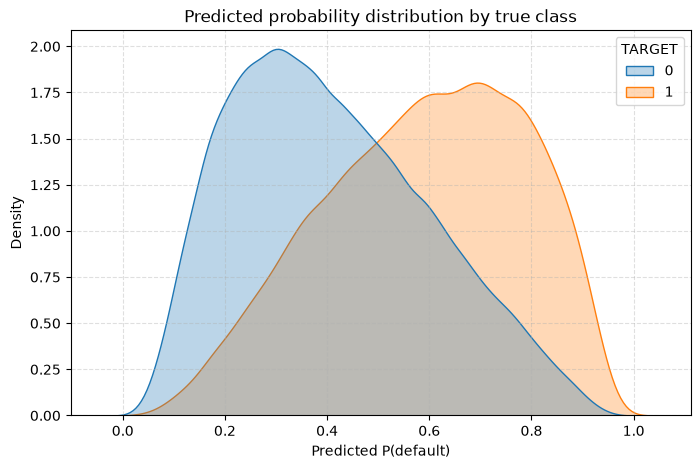

AUC score on CV: 0.7449900993276275
------------------------------
            P(no_default)  P(default)  TARGET
SK_ID_CURR                                   
100002           0.052063    0.947937       1
100003           0.752649    0.247351       0
100004           0.748701    0.251299       0
100006           0.590392    0.409608       0
100007           0.581203    0.418797       0


In [ ]:
from sklearn.linear_model import LogisticRegression

"""
 ─────────────────────────────────────────────────────────────────────────
 HOW `pipe` WORKS  (pipe = Pipeline([('preprocess', ...), ('model', ...)]))

 pipe.fit(X, y):
   1. preprocess.fit_transform(X)   -> LEARNS median/categories/min-max
                                        from X, AND transforms X using them
   2. model.fit(X_transformed, y)   -> LEARNS model params (coefs/splits/etc.)
                                        from the transformed data

 pipe.predict(Z)  /  pipe.predict_proba(Z):
   1. preprocess.transform(Z)       -> APPLIES the median/categories/min-max
                                        already learned during .fit() --
                                        does NOT relearn anything from Z
   2. model.predict(Z_transformed)  -> APPLIES the model params already
                                        learned during .fit()

   => .predict()/.predict_proba() never fit anything. Always call .fit()
      first, on raw training data, before predicting on anything.
    --      --      --      --      --      --      --      --      --    
 Rule of thumb:
   .fit() / cross_val_score() / GridSearchCV(...).fit()  -> always raw X, y
   .predict() / .predict_proba() / .transform()          -> always raw data
   (X_transformed, the standalone preprocessed snapshot, never goes back
   into pipe -- it's for inspection/plotting only.)
 ─────────────────────────────────────────────────────────────────────────
"""

pipe, X_train_ts = build_pipeline(LogisticRegression(class_weight='balanced', max_iter=500)) # NOTE class_weight='balanced'

model_eval(pipe, X)

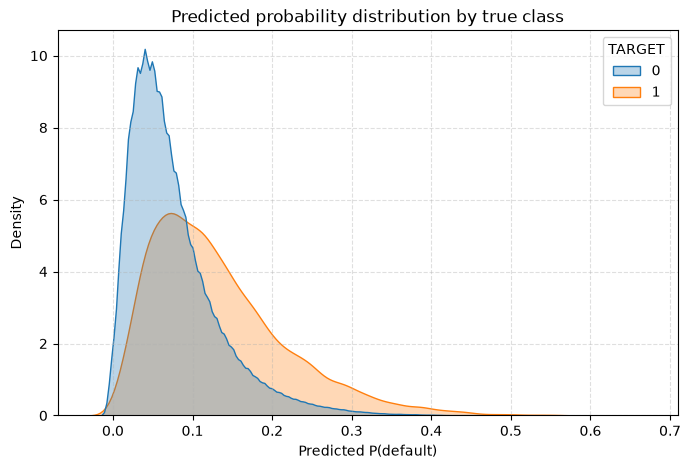

AUC score on CV: 0.7180522071258038
------------------------------
            P(no_default)  P(default)  TARGET
SK_ID_CURR                                   
100002               0.58        0.42       1
100003               0.94        0.06       0
100004               0.93        0.07       0
100006               0.94        0.06       0
100007               0.93        0.07       0


In [10]:
# Random forest

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', random_state=50, n_jobs=-1)
pipe, X_train = build_pipeline(rf)

model_eval(pipe, X)

With no extra features or feature engineering and with simple imputing/encoding we get:

Logistic: AUC = 0.7453; and an easy to distinguish distributions

Random Forest: AUC = 0.7188; and hard to distinguish distributions with similar centers.

In [11]:
# Read and store additional csv's with extra features

"""
NOTE: The index 'SK_ID_CURR' is not unique in the suplementary CSV's
so we have to groupby after taking only the relevant indexes from the clients in "X".
"""

bureau = pd.read_csv('bureau.csv')
bureau = bureau[bureau['SK_ID_CURR'].isin(X.index)].set_index('SK_ID_CURR')


ccb = pd.read_csv('credit_card_balance.csv')
ccb = ccb[ccb['SK_ID_CURR'].isin(X.index)].set_index('SK_ID_CURR')


install_pay = pd.read_csv('installments_payments.csv')
install_pay = install_pay[install_pay['SK_ID_CURR'].isin(X.index)].set_index('SK_ID_CURR')

prev_app = pd.read_csv('previous_application.csv')
prev_app = prev_app[prev_app['SK_ID_CURR'].isin(X.index)].set_index('SK_ID_CURR')

bureau_bal = pd.read_csv('bureau_balance.csv') # DOES NOT HAVE THE index column from others


In [13]:
# We group bureau.csv, install_payments.csv and CCB.csv by their index
# and we group bureau_balance by the suplementary index to create the index column

id_map = pd.Series(bureau.index, index=bureau.SK_ID_BUREAU)

bureau_bal['SK_ID_CURR'] = bureau_bal['SK_ID_BUREAU'].map(id_map)
bureau_bal = bureau_bal.dropna(subset=['SK_ID_CURR'])
bureau_bal['SK_ID_CURR'] = bureau_bal['SK_ID_CURR'].map(lambda p: int(p))
bureau_bal = bureau_bal.set_index('SK_ID_CURR')


C:\Users\aleja\AppData\Local\Temp\ipykernel_27748\220783714.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bureau_bal['SK_ID_CURR'] = bureau_bal['SK_ID_CURR'].map(lambda p: int(p))


In [14]:
# We groupby index and aggregate data so it can work with the data transformation pipeline
# NaN's are fixed AFTER aggregating

def primary_mode(x): # Helper function since 'mode' does not work in pandas
    mode_vals = x.mode()
    return mode_vals.iloc[0] if not mode_vals.empty else None


ccb_agg = ccb.groupby('SK_ID_CURR').agg({
    'AMT_BALANCE': ['mean', 'max', 'sum'],
    'AMT_PAYMENT_CURRENT': ['mean'],
    'AMT_TOTAL_RECEIVABLE': ['mean'],
    'CNT_INSTALMENT_MATURE_CUM': ['mean', 'sum'] })

install_agg = install_pay.groupby('SK_ID_CURR').agg({
    'NUM_INSTALMENT_NUMBER': ['mean', 'sum'],
    'DAYS_INSTALMENT' : ['mean', 'max'],
    'AMT_INSTALMENT' : ['mean', 'sum'],
    'AMT_PAYMENT' : ['mean', 'sum'] })

b_balance_agg = bureau_bal.groupby('SK_ID_CURR').agg({
    'STATUS' : [primary_mode],
    'MONTHS_BALANCE': ['min', 'max', 'mean']    })

bureau_agg = bureau.groupby('SK_ID_CURR').agg({
    'CREDIT_ACTIVE' : [primary_mode],
    'DAYS_CREDIT' : ['mean'],
    'CREDIT_DAY_OVERDUE' : ['mean', 'max'],
    'AMT_CREDIT_SUM': ['mean'],
    'AMT_CREDIT_SUM_DEBT': ['mean'],
    'CREDIT_TYPE' : [primary_mode]    })

prev_agg = prev_app.groupby('SK_ID_CURR').agg({
    'NAME_CONTRACT_TYPE' : [primary_mode],
    'RATE_DOWN_PAYMENT' : ['mean'],
    'NAME_CASH_LOAN_PURPOSE': [primary_mode],
    'NAME_CONTRACT_STATUS': [primary_mode],
    'CNT_PAYMENT' : ['mean']
})


In [65]:
# Merge all DF to have a single X and then split into train/test

data = pd.concat([X, ccb_agg, bureau_agg, b_balance_agg, install_agg, prev_agg], axis=1)

from sklearn.model_selection import train_test_split

train, test, y_train, y_test = train_test_split(data, y, test_size=0.2, random_state=10, stratify=y)

In [16]:
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def transform_dataframe(df):


    df.columns = ['_'.join(map(str, col)).strip() if isinstance(col, tuple) else str(col) for col in df.columns]
    
    # Replace infinite values with NaN so the SimpleImputer can handle them safely
    df = df.replace([np.inf, -np.inf], np.nan)
    
    cat = df.select_dtypes(exclude='number')
    ord_cols = [c for c in cat.columns if cat[c].fillna('Missing').nunique() <= 2]
    oh_cols  = [c for c in cat.columns if cat[c].fillna('Missing').nunique() > 2]
    num_cols = list(df.select_dtypes(include='number').columns)

    numeric_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', MinMaxScaler(feature_range=(0, 1))),
    ])
    ord_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OrdinalEncoder()),
    ])
    oh_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])

    preprocess = ColumnTransformer([
        ('num', numeric_pipe, num_cols),
        ('ord', ord_pipe, ord_cols),
        ('oh',  oh_pipe,  oh_cols),
    ])

    df_transformed = preprocess.fit_transform(df)

    if oh_cols:
        oh_names = preprocess.named_transformers_['oh'].named_steps['encoder'].get_feature_names_out(oh_cols)
        feature_names = num_cols + ord_cols + list(oh_names)
    else:
        feature_names = num_cols + ord_cols

    return pd.DataFrame(df_transformed, columns=feature_names, index=df.index)

In [66]:
# Create domain features on the raw data then transform all data
train['CREDIT_INCOME_PERCENT'] = train['AMT_CREDIT'] / train['AMT_INCOME_TOTAL']
train['ANNUITY_INCOME_PERCENT'] = train['AMT_ANNUITY'] / train['AMT_INCOME_TOTAL']
train['CREDIT_TERM'] = train['AMT_ANNUITY'] / train['AMT_CREDIT']
train['DAYS_EMPLOYED_PERCENT'] = train['DAYS_EMPLOYED'] / train['DAYS_BIRTH']

test['CREDIT_INCOME_PERCENT'] = test['AMT_CREDIT'] / test['AMT_INCOME_TOTAL']
test['ANNUITY_INCOME_PERCENT'] = test['AMT_ANNUITY'] / test['AMT_INCOME_TOTAL']
test['CREDIT_TERM'] = test['AMT_ANNUITY'] / test['AMT_CREDIT']
test['DAYS_EMPLOYED_PERCENT'] = test['DAYS_EMPLOYED'] / test['DAYS_BIRTH']


train_ts = transform_dataframe(train)
test_ts = transform_dataframe(test)

In [18]:
# Modifies to run with already transformed data instead of pipeline

def model_eval_ts(model, df_transformed, y):
    """
    Evaluates a model on already transformed data using out-of-fold predictions.
    """
    # Pass the standalone model and the pre-processed dataframe
    predicts = cross_val_predict(model, df_transformed, y, cv=3, method='predict_proba')
    
    # Calculate pooled AUC over all out-of-fold predictions
    roc = roc_auc_score(y, predicts[:, 1])   
    
    # Build the prediction dataframe
    pred_df = pd.DataFrame(predicts, columns=['P(no_default)', 'P(default)'], index=y.index)
    pred_df['TARGET'] = y.values

    # Plot the distributions
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.kdeplot(data=pred_df, x='P(default)', hue='TARGET', common_norm=False, fill=True, alpha=0.3, ax=ax)
    ax.set_xlabel('Predicted P(default)')
    ax.set_title('Predicted probability distribution by true class')
    ax.grid(True, linestyle='--', alpha=0.4)
    plt.show()

    # Print results
    print(f'AUC score on CV: {roc:.4f}')
    print('------------------------------')
    print(pred_df.head())

c:\Users\aleja\.conda\envs\opt_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\aleja\.conda\envs\opt_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\aleja\.conda\envs\opt_env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\aleja\.conda\envs\opt_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: '

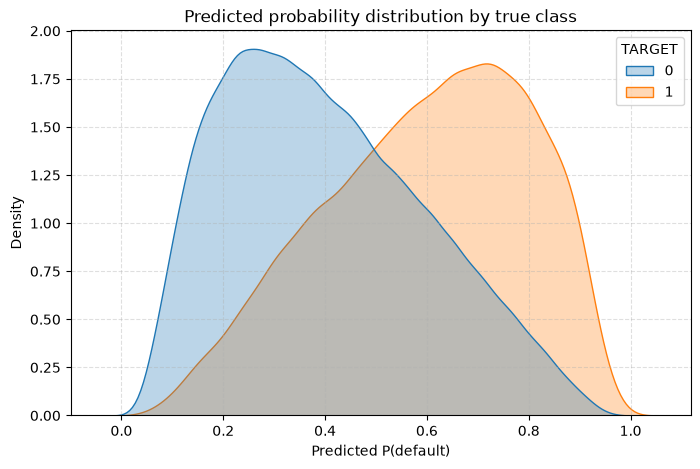

AUC score on CV: 0.7573
------------------------------
            P(no_default)  P(default)  TARGET
SK_ID_CURR                                   
230506           0.580525    0.419475       0
267896           0.859886    0.140114       0
265112           0.647375    0.352625       0
103637           0.717538    0.282462       0
169482           0.788247    0.211753       0


In [19]:
model = LogisticRegression(penalty='l1', solver='saga', C=0.1, class_weight='balanced')

model_eval_ts(model, train_ts, y_train)

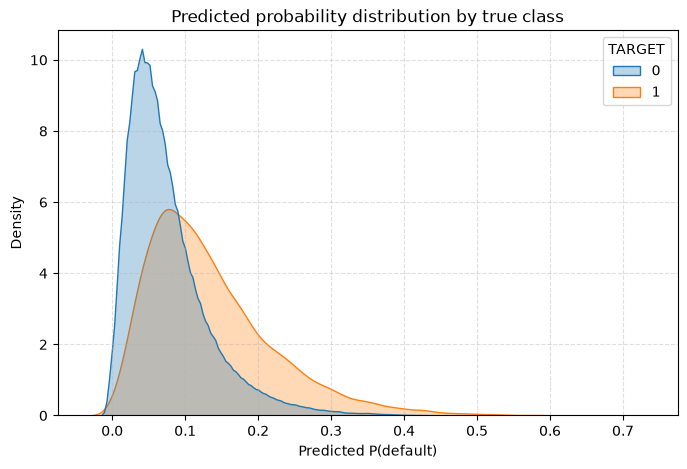

AUC score on CV: 0.7303
------------------------------
            P(no_default)  P(default)  TARGET
SK_ID_CURR                                   
230506               0.95        0.05       0
267896               0.99        0.01       0
265112               1.00        0.00       0
103637               0.97        0.03       0
169482               0.98        0.02       0


In [20]:
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', random_state=50, n_jobs=-1)

model_eval_ts(rf, train_ts, y_train)

In [21]:
# Exctract important/unimportant features
rf.fit(train_ts, y_train)

importances = rf.feature_importances_
feature_names = train_ts.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print(importance_df.head(10))
print(importance_df.tail(10))

                 Feature  Importance
0           EXT_SOURCE_2    0.048228
1           EXT_SOURCE_3    0.044832
2             DAYS_BIRTH    0.022148
3            CREDIT_TERM    0.021994
4           EXT_SOURCE_1    0.020885
5       DAYS_CREDIT_mean    0.020369
6  DAYS_EMPLOYED_PERCENT    0.019497
7        DAYS_ID_PUBLISH    0.018137
8      DAYS_REGISTRATION    0.017763
9            AMT_ANNUITY    0.017728
                                               Feature    Importance
323      CREDIT_TYPE_primary_mode_Unknown type of loan  3.187446e-07
324  CREDIT_TYPE_primary_mode_Loan for working capi...  7.338001e-08
325  CREDIT_TYPE_primary_mode_Loan for the purchase...  1.925480e-20
326                                         FLAG_MOBIL  1.250469e-20
327  NAME_CASH_LOAN_PURPOSE_primary_mode_Money for ...  0.000000e+00
328                         NAME_FAMILY_STATUS_Unknown  0.000000e+00
329                       NAME_INCOME_TYPE_Businessman  0.000000e+00
330                                    CO

# Polynomial features and removal of unimportant features

In [27]:
# We remove the least important features by Random Forest importance and create poly features
"""
We found through several variations of selecting the "top k features" that 
including all features yields a higher AUC unless we select most features.
At that point removal of features seems slightly beneficial
250 features seems the neighbourhood that works best
"""
t250 = list(importance_df.Feature.iloc[:250])
trunc_train_ts = train_ts.loc[ : , t250]

topK = list(importance_df.Feature.iloc[:15])
poly_features = train_ts[topK]

from sklearn.preprocessing import PolynomialFeatures
poly_transformer = PolynomialFeatures(degree=2)

poly_features = poly_transformer.fit_transform(poly_features)

poly_features = pd.DataFrame(
    poly_features, columns=poly_transformer.get_feature_names_out(topK), index=train_ts.index )

names = poly_transformer.get_feature_names_out(topK)

train_poly = pd.concat([trunc_train_ts, poly_features], axis=1)

train_poly = train_poly.loc[:, ~train_poly.columns.duplicated()]


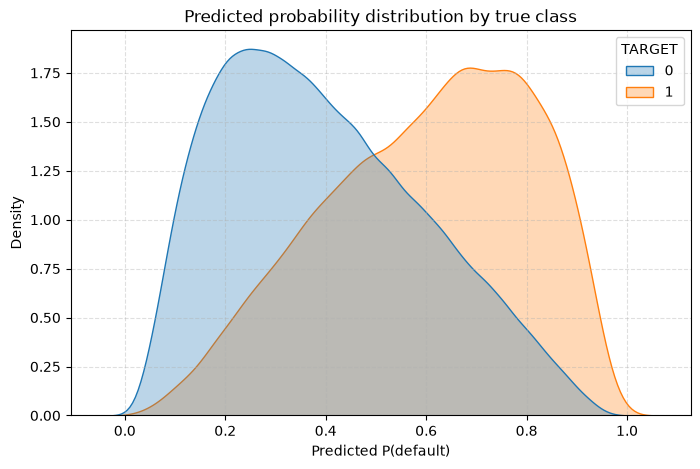

AUC score on CV: 0.7611
------------------------------
            P(no_default)  P(default)  TARGET
SK_ID_CURR                                   
230506           0.596856    0.403144       0
267896           0.833274    0.166726       0
265112           0.731762    0.268238       0
103637           0.637872    0.362128       0
169482           0.852981    0.147019       0


In [28]:
model = LogisticRegression(class_weight='balanced', max_iter=500)

model_eval_ts(model, train_poly, y_train); # Slight improvement, finally reached 0.76 AUC

# WoE-transformed features

### WoE-transformed features — summary

**Weight of Evidence (WoE):** for each bin $i$ of a variable, with $p_i^{NE}$ = fraction of all
non-events (goods) in that bin and $p_i^{E}$ = fraction of all events (defaults) in that bin,

$$\text{WoE}_i = \ln\left(\frac{p_i^{NE}}{p_i^{E}}\right)$$

WoE moves *opposite* to the bin's default rate: safe bins → positive WoE, risky bins → negative WoE.

**Information Value (IV):** per-bin contribution $IV_i = (p_i^{NE}-p_i^E)\cdot \text{WoE}_i$, summed
over bins to get the variable's total IV. This is the Jeffreys divergence (symmetrized KL) between
the non-event and event distributions across bins — used below to triage features
(rule of thumb: <0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, 0.3–0.5 strong, >0.5 suspicious/leaky).

**How the bins are chosen (`optbinning.BinningProcess`):**
- *Numeric variables:* fine pre-binning (quantiles/tree splits) is merged into final bins by
  maximizing total IV subject to a **monotonicity constraint** on WoE/event rate and a
  **minimum bin size** (`min_bin_size=0.05` here → each bin holds ≥5% of rows, to avoid
  overfit, fragmented bins).
- *Categorical variables:* categories are first ordered by empirical event rate, turning the
  problem into the same monotonic-merge search, then adjacent categories are grouped —
  this replaces one-hot/ordinal encoding entirely.

**Missing/infinite values:** engineered ratio features can produce $\pm\infty$ from division by
zero; these are replaced with `NaN` before fitting so they land in a dedicated **Missing bin**
with its own WoE (computed from whichever event rate the missing rows actually have), rather
than distorting the split search for real values.

**Fitting discipline:** `binning_process.fit()` is called on the train split only, and the
learned bin edges/WoE values are then applied via `.transform()` to both train and test —
same fit/transform discipline as the rest of the pipeline, to avoid leakage.

In [78]:
from optbinning import BinningProcess

train_raw = train.replace([np.inf, -np.inf], np.nan)
test_raw  = test.replace([np.inf, -np.inf], np.nan)

# Identify categoricals from the RAW (unencoded) frame -- optbinning bins
# numeric and categorical variables in one pass, so we skip separate
# ordinal/one-hot handling entirely for this track
cat_cols = list(train_raw.select_dtypes(exclude='number').columns)
variable_names = list(train_raw.columns)


binning_process = BinningProcess(
    variable_names=variable_names,
    categorical_variables=cat_cols,
    min_bin_size=0.05
)

# Fit ONLY on train
binning_process.fit(train_raw[variable_names], y_train)

# Apply the learned bin edges/WoE values to both splits
train_woe = binning_process.transform(train_raw[variable_names], metric='woe')
test_woe  = binning_process.transform(test_raw[variable_names], metric='woe')

                 Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.15)   14408   0.058567      11335   3073    0.213284   
1       [0.15, 0.26)   16557   0.067303      14265   2292    0.138431   
2       [0.26, 0.33)   16840   0.068453      14926   1914    0.113658   
...              ...     ...        ...        ...    ...         ...   
14           Special       0   0.000000          0      0    0.000000   
15           Missing     524   0.002130        485     39    0.074427   
Totals                246008   1.000000     226148  19860    0.080729   

             WoE        IV        JS  
0      -1.127241  0.117922  0.014006  
1      -0.604098  0.031612  0.003893  
2      -0.378573  0.011499  0.001429  
...          ...       ...       ...  
14           0.0  0.000000  0.000000  
15      0.088105  0.000016  0.000002  
Totals            0.319725  0.038593  

[17 rows x 9 columns]


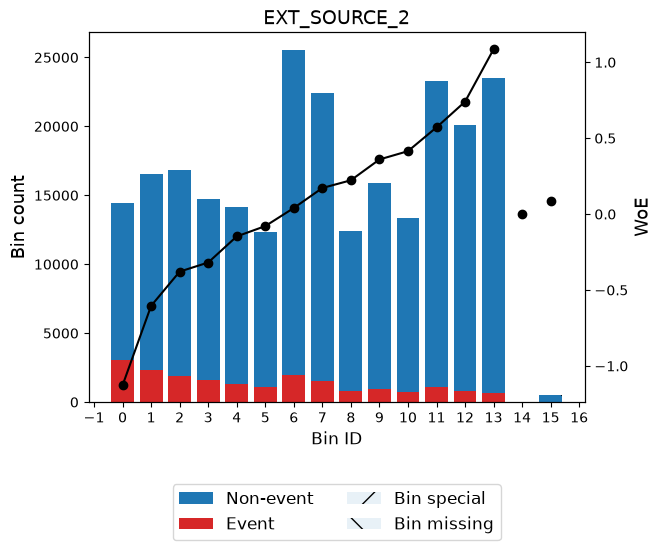

Bin 14: Special category bin;    Bin 15: Missing values Bin


,name,dtype,status,selected,n_bins,iv,js,gini,quality_score
42,EXT_SOURCE_3,numerical,OPTIMAL,True,12,0.341373,0.041227,0.318663,0.140073
41,EXT_SOURCE_2,numerical,OPTIMAL,True,14,0.319725,0.038593,0.310203,0.398859
40,EXT_SOURCE_1,numerical,OPTIMAL,True,6,0.151137,0.018355,0.18071,0.426873
...,...,...,...,...,...,...,...,...,...
112,FLAG_DOCUMENT_19,numerical,OPTIMAL,True,1,0.0,0.0,0,0.0
113,FLAG_DOCUMENT_20,numerical,OPTIMAL,True,1,0.0,0.0,0,0.0
0,TARGET,numerical,OPTIMAL,True,1,0.0,0.0,0,0.0


In [79]:
# Inspect one variable's bin edges, WoE, and IV
optb = binning_process.get_binned_variable('EXT_SOURCE_2')
print(optb.binning_table.build())
optb.binning_table.plot(metric='woe')
print('Bin 14: Special category bin;    Bin 15: Missing values Bin')

# IV/Gini summary across all variables, for feature triage
binning_process.summary().sort_values('iv', ascending=False)

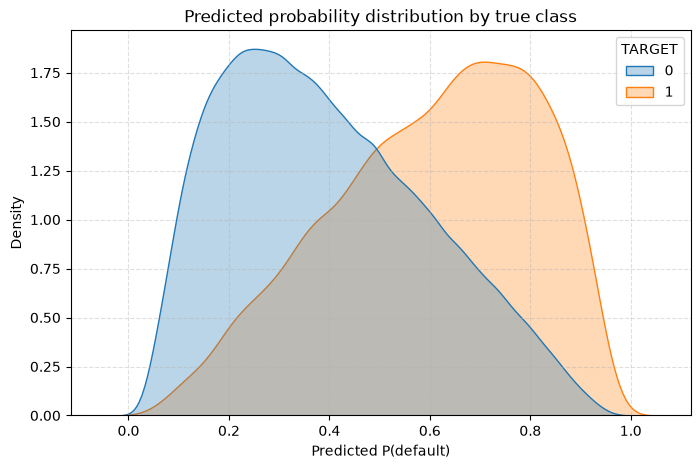

AUC score on CV: 0.7646
------------------------------
            P(no_default)  P(default)  TARGET
SK_ID_CURR                                   
230506           0.398150    0.601850       0
267896           0.831226    0.168774       0
265112           0.791809    0.208191       0
103637           0.623504    0.376496       0
169482           0.797508    0.202492       0


In [84]:
model = LogisticRegression(class_weight='balanced', max_iter=500, C = 0.1)
model_eval_ts(model, train_woe, y_train)

                           Bin   Count  Count (%)  Non-event  Event  \
0            (-inf, -23181.50)   12613   0.051271      12069    544   
1       [-23181.50, -21849.50)   16599   0.067473      15716    883   
2       [-21849.50, -19969.50)   27518   0.111858      25969   1549   
...                        ...     ...        ...        ...    ...   
12                     Special       0   0.000000          0      0   
13                     Missing       0   0.000000          0      0   
Totals                          246008   1.000000     226148  19860   

        Event rate       WoE        IV        JS  
0         0.043130  0.666964  0.017325  0.002126  
1         0.053196  0.446627  0.011180  0.001386  
2         0.056290  0.386812  0.014249  0.001770  
...            ...       ...       ...       ...  
12        0.000000       0.0  0.000000  0.000000  
13        0.000000       0.0  0.000000  0.000000  
Totals    0.080729            0.086258  0.010693  

[15 rows x 9 columns]


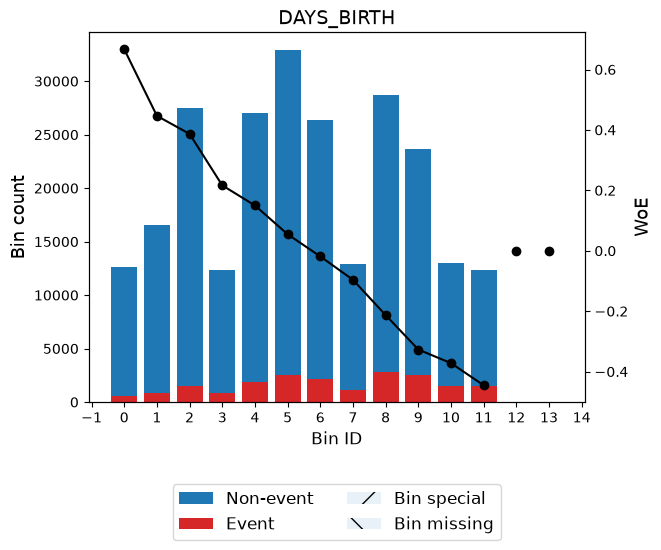

In [81]:
optb = binning_process.get_binned_variable('DAYS_BIRTH')
print(optb.binning_table.build())
optb.binning_table.plot(metric='woe')

# Hyperparameter search

In [50]:
from sklearn.model_selection import GridSearchCV

log_reg = LogisticRegression(max_iter=500, class_weight='balanced')

param_grid = [
    {
        'solver': ['saga'],
        'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
        'l1_ratio': [0.0, 0.25, 0.5, 1.0]
    }
]

grid_search = GridSearchCV(log_reg, param_grid, cv=3, scoring='roc_auc', return_train_score=True,n_jobs=-1)

grid_search.fit(train_woe, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre... max_iter=500)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'C': [0.001, 0.01, ...], 'l1_ratio': [0.0, 0.25, ...], 'solver': ['saga']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r

In [51]:
# 1. Print the absolute best score and parameters
print("=" * 60)
print(f"Best ROC-AUC Score: {grid_search.best_score_:.5f}")
print(f"Best Parameters:    {grid_search.best_params_}")
print("=" * 60)

# 2. Convert cv_results_ to a DataFrame
results = pd.DataFrame(grid_search.cv_results_)

# 3. Extract and rename the columns we care about
relevant_cols = {
    'param_C': 'C',
    'param_l1_ratio': 'l1_ratio',
    'mean_test_score': 'Mean CV ROC-AUC',
    'std_test_score': 'CV Std Dev',
    'mean_train_score': 'Mean Train ROC-AUC' # Included because return_train_score=True
}

results_df = results[list(relevant_cols.keys())].rename(columns=relevant_cols)

# Sort by validation score to see the best combinations at the top
results_df = results_df.sort_values(by='Mean CV ROC-AUC', ascending=False)

# Display the top 10 configurations
print("\n--- TOP 10 HYPERPARAMETER COMBINATIONS ---")
print(results_df.head(10).to_string(index=False, formatters={
    'C': '{:.3f}'.format,
    'l1_ratio': '{:.2f}'.format,
    'Mean CV ROC-AUC': '{:.5f}'.format,
    'CV Std Dev': '{:.5f}'.format,
    'Mean Train ROC-AUC': '{:.5f}'.format
}))

Best ROC-AUC Score: 0.76476
Best Parameters:    {'C': 0.1, 'l1_ratio': 1.0, 'solver': 'saga'}

--- TOP 10 HYPERPARAMETER COMBINATIONS ---
     C l1_ratio Mean CV ROC-AUC CV Std Dev Mean Train ROC-AUC
 0.100     1.00         0.76476    0.00136            0.76682
 0.100     0.50         0.76472    0.00142            0.76692
 0.100     0.25         0.76467    0.00147            0.76697
 0.100     0.00         0.76460    0.00151            0.76703
 1.000     0.50         0.76439    0.00172            0.76726
 1.000     0.00         0.76439    0.00171            0.76726
 1.000     0.25         0.76439    0.00172            0.76726
 1.000     1.00         0.76438    0.00173            0.76725
10.000     0.00         0.76425    0.00182            0.76730
10.000     0.25         0.76425    0.00183            0.76730


In [87]:
# Final metric inspection with actual test set.

log = LogisticRegression(C=0.1, l1_ratio=1, solver='saga', max_iter=500)

log.fit(train_woe, y_train)
preds = log.predict(test_woe)

from sklearn.metrics import f1_score, roc_auc_score, precision_score

print(f'F_1 score: {f1_score(y_test, preds)}')
print(f'Precision: {precision_score(y_test, preds)}')
print(f'AUC score: {roc_auc_score(y_test, preds)}')

from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, preds)

F_1 score: 0.037911025145067695
Precision: 0.47804878048780486
AUC score: 0.508922817357072


array([[56431,   107],
       [ 4867,    98]])

# XGB Boost model